# RiceVision AI

# Notebook 05 - Model Evaluation

## Objective

Evaluate the trained EfficientNet-B0 model on the unseen test dataset.

### Evaluation Metrics

- Test Accuracy
- Precision
- Recall
- F1 Score
- Classification Report
- Confusion Matrix
- Prediction Visualization
- Misclassified Images

In [3]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

In [4]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [5]:
import torch
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

from src.config import *
from src.dataset import get_dataloaders
from src.model import build_model
from src.utils import load_checkpoint

In [6]:
train_loader, val_loader, test_loader = get_dataloaders()

print("Test Batches :", len(test_loader))

Test Batches : 28


In [7]:
model = build_model()

model = load_checkpoint(
    model,
    MODEL_PATH / "best_model.pth",
    DEVICE
)

model.to(DEVICE)
model.eval()

print("Best model loaded successfully.")

Best model loaded successfully.


In [8]:
y_true = []
y_pred = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(images)

        _, preds = torch.max(outputs, 1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

In [9]:
print(classification_report(
    y_true,
    y_pred,
    target_names=CLASS_NAMES
))

                 precision    recall  f1-score   support

Bacterialblight       0.99      0.99      0.99       238
          Blast       0.99      0.99      0.99       216
      Brownspot       1.00      1.00      1.00       240
         Tungro       1.00      1.00      1.00       196

       accuracy                           0.99       890
      macro avg       0.99      0.99      0.99       890
   weighted avg       0.99      0.99      0.99       890



In [10]:
accuracy = np.mean(
    np.array(y_true) == np.array(y_pred)
)

print(f"Test Accuracy : {accuracy:.4f}")

Test Accuracy : 0.9933


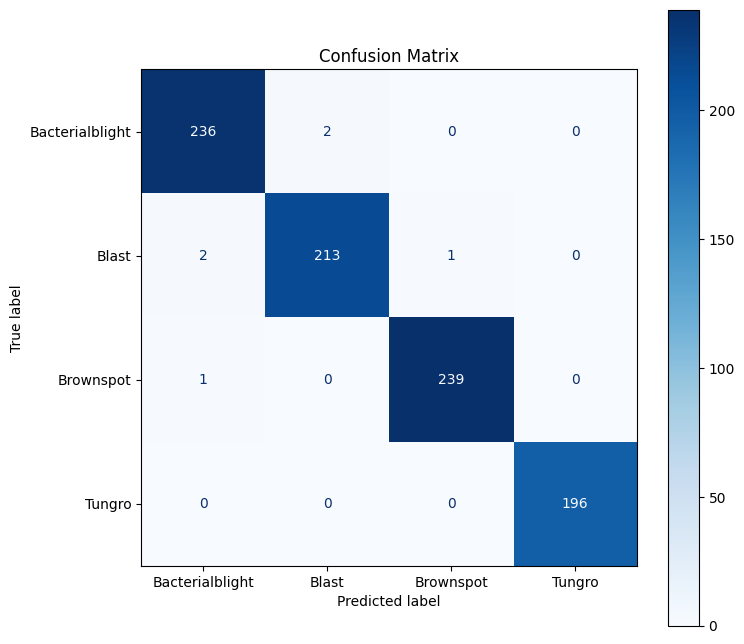

In [11]:
cm = confusion_matrix(
    y_true,
    y_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

fig, ax = plt.subplots(figsize=(8,8))

disp.plot(
    cmap="Blues",
    ax=ax
)

plt.title("Confusion Matrix")

plt.show()

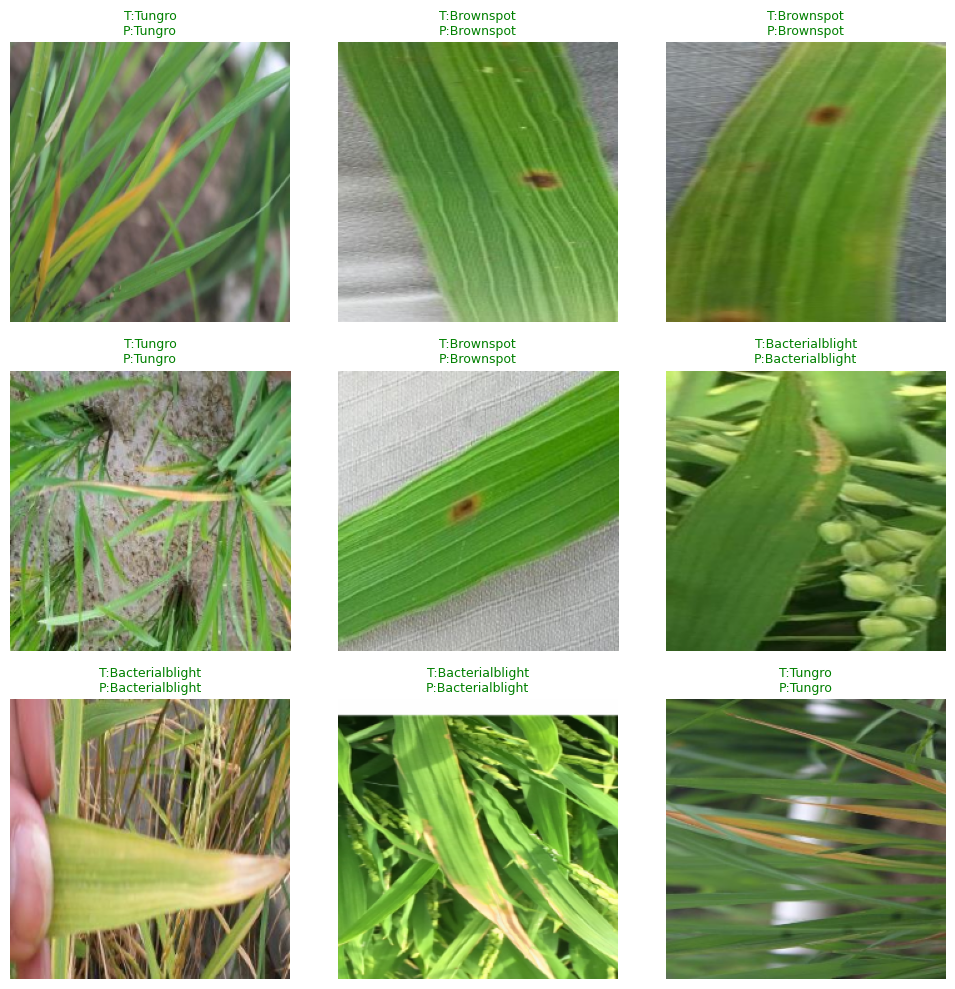

In [12]:
mean = np.array(MEAN)
std = np.array(STD)

images, labels = next(iter(test_loader))

images = images[:9]
labels = labels[:9]

outputs = model(images.to(DEVICE))

_, preds = torch.max(outputs, 1)

fig, axes = plt.subplots(3,3, figsize=(10,10))

for i, ax in enumerate(axes.flat):

    image = images[i].permute(1,2,0).numpy()

    image = image * std + mean
    image = np.clip(image,0,1)

    ax.imshow(image)

    true_label = CLASS_NAMES[labels[i]]
    pred_label = CLASS_NAMES[preds[i]]

    color = "green" if true_label == pred_label else "red"

    ax.set_title(
        f"T:{true_label}\nP:{pred_label}",
        color=color,
        fontsize=9
    )

    ax.axis("off")

plt.tight_layout()

plt.show()

In [13]:
misclassified = []

with torch.no_grad():

    for images, labels in test_loader:

        outputs = model(images.to(DEVICE))

        _, preds = torch.max(outputs,1)

        for img,true,pred in zip(images,labels,preds.cpu()):

            if true != pred:

                misclassified.append(
                    (img,true,pred)
                )

In [14]:
print(f"Total Misclassified : {len(misclassified)}")

Total Misclassified : 6


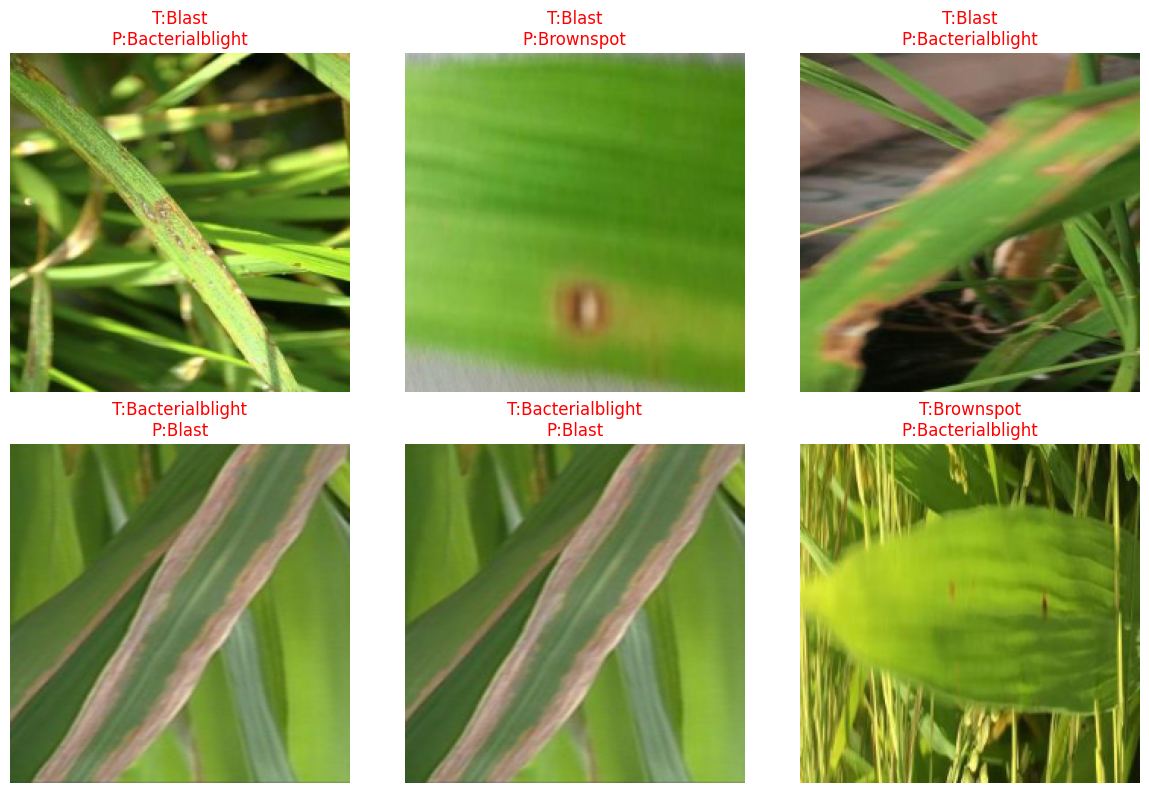

In [15]:
fig, axes = plt.subplots(2,3, figsize=(12,8))

for ax,(img,true,pred) in zip(
    axes.flat,
    misclassified[:6]
):

    image = img.permute(1,2,0).numpy()

    image = image * std + mean
    image = np.clip(image,0,1)

    ax.imshow(image)

    ax.set_title(
        f"T:{CLASS_NAMES[true]}\nP:{CLASS_NAMES[pred]}",
        color="red"
    )

    ax.axis("off")

plt.tight_layout()

plt.show()

In [16]:
import torch

torch.save(
    model.state_dict(),
    MODEL_PATH / "efficientnet_b0_baseline.pth"
)

print("Baseline model saved.")

Baseline model saved.


In [17]:
# import pandas as pd

# history_df = pd.DataFrame(history)

# history_df.to_csv(
#     OUTPUT_PATH / "training_history.csv",
#     index=False
# )

# history_df.head()

In [18]:
# print(type(history))

In [19]:
%whos

Variable                 Type                      Data/Info
------------------------------------------------------------
BATCH_SIZE               int                       32
CLASS_NAMES              list                      n=4
ConfusionMatrixDisplay   type                      <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
DATASET_PATH             WindowsPath               D:\Jupyter\CropDisease\Rice Leaf Disease Images
DEVICE                   device                    cpu
EPOCHS                   int                       20
IMAGE_SIZE               int                       224
LEARNING_RATE            float                     0.001
MEAN                     tuple                     n=3
MODEL_NAME               str                       efficientnet_b0
MODEL_PATH               WindowsPath               D:\Jupyter\CropDisease\models
NUM_CLASSES              int                       4
NUM_WORKERS              int                       0
OUTPUT_PATH              WindowsP

# Notebook Summary

## Completed

- Loaded trained EfficientNet-B0 model
- Evaluated on unseen test dataset
- Computed classification metrics
- Generated confusion matrix
- Visualized predictions
- Analyzed misclassified images

## Generated Outputs

- Test Accuracy
- Precision
- Recall
- F1 Score
- Classification Report
- Confusion Matrix
- Prediction Samples
- Misclassification Analysis

## Next Notebook

Notebook 06 – Grad-CAM Explainability

The next notebook will visualize the regions of the rice leaf that influenced the model's predictions, improving interpretability and making the system more useful for agricultural decision support.

In [20]:
from src.model import build_model
from src.utils import load_checkpoint

model = build_model(pretrained=False)

model = load_checkpoint(
    model,
    MODEL_PATH / "best_model.pth",
    DEVICE
)

model.eval()

EfficientNet(
  (conv_stem): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (bn1): BatchNormAct2d(
    32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
    (drop): Identity()
    (act): SiLU(inplace=True)
  )
  (blocks): Sequential(
    (0): Sequential(
      (0): DepthwiseSeparableConv(
        (conv_dw): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
        (bn1): BatchNormAct2d(
          32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
          (drop): Identity()
          (act): SiLU(inplace=True)
        )
        (aa): Identity()
        (se): SqueezeExcite(
          (conv_reduce): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
          (act1): SiLU(inplace=True)
          (conv_expand): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
          (gate): Sigmoid()
        )
        (conv_pw): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn2

In [21]:
from PIL import Image
from torchvision import transforms
import torch

image = Image.open(
    r"D:\Jupyter\CropDisease\test_images\IMG_20190419_095429.jpg"
).convert("RGB")

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

input_tensor = transform(image).unsqueeze(0).to(DEVICE)

In [22]:
with torch.no_grad():

    output = model(input_tensor)

    probabilities = torch.softmax(output, dim=1)

    confidence, predicted = torch.max(probabilities, 1)

print("Probabilities:")
print(probabilities)

print()

print("Predicted Index:", predicted.item())

print("Predicted Class:", CLASS_NAMES[predicted.item()])

print("Confidence:", confidence.item())

Probabilities:
tensor([[0.0012, 0.0253, 0.0161, 0.9574]])

Predicted Index: 3
Predicted Class: Tungro
Confidence: 0.9574298858642578
